# Diffusion 확산 모델 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week15/diffusion/lab/diffusion.ipynb)

노이즈를 1,000번 나눠 섞고 ($\mathbf{x}_t = \sqrt{\bar\alpha_t}\mathbf{x}_0 + \sqrt{1-\bar\alpha_t}\boldsymbol\epsilon$), 섞인 노이즈를 맞히도록 학습한 뒤, 노이즈에서 시작해 조금씩 지운다.

- **파트 1**: 노이즈 스케줄 · 한 번에 섞기
- **파트 2**: 손글씨 숫자 DDPM 학습
- **파트 3**: 1,000단계 vs 50단계 생성, 종류 · 확신

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 파트 2 는 1 ~ 3분 걸린다.

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression

## 파트 1. 스케줄 · 섞기

In [ ]:
T = 1000
beta = torch.linspace(1e-4, 0.02, T)
alpha = 1 - beta
abar = torch.cumprod(alpha, 0)                           # abar[t-1] = product of (1 - beta) up to step t
for t in [1, 100, 250, 500, 750, 1000]:
    print(f"t = {t:4d}: image x {abar[t - 1].sqrt():.2f} + noise x {(1 - abar[t - 1]).sqrt():.2f}")

digits = load_digits()
X = torch.tensor(digits.data / 8.0 - 1.0, dtype=torch.float32)   # pixels in [-1, 1]

def add_noise(x0, t, eps):
    a = abar[t - 1]
    return None  # TODO: mix image and noise for step t

eps = torch.randn(64, generator=torch.Generator().manual_seed(1))
fig, axs = plt.subplots(1, 6, figsize=(10, 2))
for ax, t in zip(axs, [1, 100, 250, 500, 750, 1000]):
    ax.imshow(add_noise(X[0], t, eps).reshape(8, 8), cmap="gray_r", vmin=-1.5, vmax=1.5); ax.set_title(f"t = {t}"); ax.axis("off")
plt.show()

**예상 결과**

```
t =    1: image x 1.00 + noise x 0.01
t =  100: image x 0.95 + noise x 0.32
t =  250: image x 0.72 + noise x 0.69
t =  500: image x 0.28 + noise x 0.96
t =  750: image x 0.06 + noise x 1.00
t = 1000: image x 0.01 + noise x 1.00
```

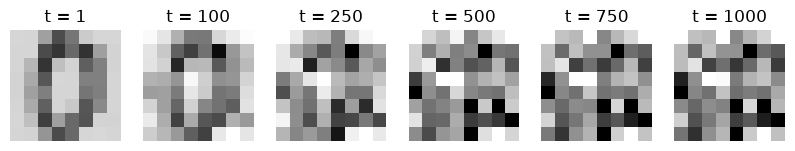

## 파트 2. 노이즈 맞히기 학습

신경망 $f(\mathbf{x}_t, t)$: 그림 64칸 + 단계 $t$ 를 사인 · 코사인 64칸으로 → 섞인 노이즈 64칸.

In [ ]:
def time_embedding(t, dim=64):
    freq = torch.exp(-math.log(10000) * torch.arange(dim // 2) / (dim // 2))
    a = t[:, None].float() * freq[None]
    return torch.cat([a.sin(), a.cos()], 1)

torch.manual_seed(0)
net = nn.Sequential(nn.Linear(128, 512), nn.SiLU(), nn.Linear(512, 512), nn.SiLU(), nn.Linear(512, 512), nn.SiLU(), nn.Linear(512, 64))
predict_noise = lambda x, t: net(torch.cat([x, time_embedding(t)], 1))

def train(X, steps=30000):
    opt = torch.optim.Adam(net.parameters(), 1e-3); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for it in range(steps):
        x0 = X[torch.randint(0, len(X), (256,))]
        t = torch.randint(1, T + 1, (256,)); eps = torch.randn_like(x0)
        xt = abar[t - 1].sqrt()[:, None] * x0 + (1 - abar[t - 1]).sqrt()[:, None] * eps
        loss = None  # TODO: mean squared error of the predicted noise
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if it % 5000 == 0:
            print(f"step {it}: loss {loss.item():.3f}")

train(X)

**예상 결과**

```
step 0: loss 1.003
step 5000: loss 0.123
step 10000: loss 0.098
step 15000: loss 0.099
step 20000: loss 0.077
step 25000: loss 0.087
```

## 파트 3. 노이즈에서 숫자로

In [ ]:
@torch.no_grad()
def sample_ddpm(n, seed=1):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 64, generator=g)
    for t in range(T - 1, -1, -1):                       # index t = step t+1
        eps = predict_noise(x, torch.full((n,), t))
        x = (x - beta[t] / (1 - abar[t]).sqrt() * eps) / alpha[t].sqrt()   # remove a little of the predicted noise
        if t > 0:
            x = x + beta[t].sqrt() * torch.randn(n, 64, generator=g)
    return x.clamp(-1, 1)

@torch.no_grad()
def sample_ddim(n, steps, seed=1):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 64, generator=g)
    ts = np.linspace(T - 1, 0, steps).round().astype(int)
    for i, t in enumerate(ts):
        eps = predict_noise(x, torch.full((n,), int(t)))
        x0 = (x - (1 - abar[t]).sqrt() * eps) / abar[t].sqrt()   # guess of the clean image
        if i + 1 < len(ts):
            tn = ts[i + 1]; x = abar[tn].sqrt() * x0 + (1 - abar[tn]).sqrt() * eps
        else:
            x = x0
    return x.clamp(-1, 1)

clf = LogisticRegression(max_iter=2000).fit(digits.data / 16.0, digits.target)
def judge(x):
    p = clf.predict_proba((x.numpy() + 1) / 2)
    return np.bincount(p.argmax(1), minlength=10).tolist(), float((p.max(1) >= 0.9).mean())

for name, x in [("DDPM 1000 steps", sample_ddpm(2000)), ("DDIM 50 steps", sample_ddim(2000, 50))]:
    counts, conf = judge(x)
    print(f"{name}: counts {counts}, confident {conf:.0%}")
fig, axs = plt.subplots(2, 8, figsize=(10, 2.8))
for ax, im in zip(axs.flat, x[:16]):
    ax.imshow(im.reshape(8, 8), cmap="gray_r"); ax.axis("off")
plt.show()

**예상 결과**

```
DDPM 1000 steps: counts [175, 205, 185, 225, 195, 186, 219, 193, 198, 219], confident 55%
DDIM 50 steps: counts [155, 225, 194, 214, 190, 188, 186, 226, 215, 207], confident 49%
```

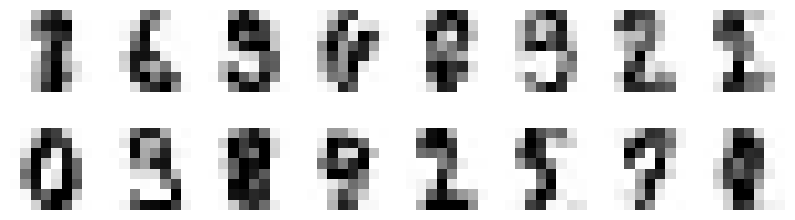

**확인 질문**
1. 파트 1 에서 그림과 노이즈의 비율이 반반 (0.71 : 0.71) 이 되는 단계는 대략 언제인가?
2. 파트 2 의 손실이 0 이 될 수 없는 이유는? (힌트: t = 1000 근처에서는 무엇을 맞혀야 할까)
3. 파트 3 에서 DDIM 단계를 10, 5, 2 로 줄이면 그림은 어떻게 될까?
4. (도전) 학습 걸음을 5,000 으로 줄이면 확신 비율은 얼마나 떨어질까?